# Analyse de corrélation (prix, quantités, délais, CA)

## Objectif
Comprendre quelles variables expliquent le chiffre d’affaires et les volumes vendus :
- prix produit vs quantité vendue
- délai de livraison vs montant/volume
- relations entre métriques commerciales (CA, quantités, fréquence de commande)

## Intérêt métier
Cette analyse aide à :
- détecter des leviers de performance (ex : volume tiré par bas prix, ou premium rentable),
- identifier des signaux logistiques (délais longs associés à baisse de volume),
- orienter les décisions (pricing, stock, politique de livraison, ciblage commercial).

## Justification de l’analyse
La corrélation mesure la force d’association entre variables :
- **Pearson** : lien linéaire (utile pour métriques continues),
- **Spearman** : lien monotone (plus robuste si distributions asymétriques / outliers).
Une **heatmap** rend la lecture immédiate et exploitable (repérage rapide des couples de variables à fort lien).

In [7]:
from pathlib import Path
import sys

# Détecter la racine du projet (celle qui contient requirements.txt + src + visualizations)
PROJECT_ROOT = None
for p in Path().resolve().parents:
    if (p / "requirements.txt").exists() and (p / "src").exists() and (p / "visualizations").exists():
        PROJECT_ROOT = p
        break

if PROJECT_ROOT is None:
    raise RuntimeError("Impossible de trouver la racine du projet (requirements.txt / src / visualizations).")

# Ajouter la racine au PYTHONPATH pour importer src.*
sys.path.append(str(PROJECT_ROOT))

# Dossier de sortie des figures
OUTPUT_DIR = PROJECT_ROOT / "visualizations" / "part4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT, OUTPUT_DIR

(WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis'),
 WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis/visualizations/part4'))

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from src.analysis.db import get_connection

def fetch_df(query, params=None):
    conn = get_connection()
    df = pd.read_sql(query, conn, params=params)
    conn.close()
    return df

In [9]:
conn = get_connection()
print(conn)
conn.close()

In [10]:
sql = """
SELECT
    od.orderNumber,
    o.orderDate,
    o.shippedDate,
    DATEDIFF(o.shippedDate, o.orderDate) AS shipping_delay_days,

    od.productCode,
    od.quantityOrdered,
    od.priceEach,
    (od.quantityOrdered * od.priceEach) AS line_revenue,

    p.productLine,
    p.buyPrice,
    (od.priceEach - p.buyPrice) AS unit_margin,
    ((od.priceEach - p.buyPrice) * od.quantityOrdered) AS line_margin
FROM orderdetails od
JOIN orders o ON o.orderNumber = od.orderNumber
JOIN products p ON p.productCode = od.productCode
WHERE o.shippedDate IS NOT NULL;
"""

df = fetch_df(sql)
df.head(), df.shape


C:\Users\canpe\AppData\Local\Temp\ipykernel_10324\2371453190.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


(   orderNumber   orderDate shippedDate  shipping_delay_days productCode  \
 0        10100  2003-01-06  2003-01-10                    4    S18_1749   
 1        10100  2003-01-06  2003-01-10                    4    S18_2248   
 2        10100  2003-01-06  2003-01-10                    4    S18_4409   
 3        10100  2003-01-06  2003-01-10                    4    S24_3969   
 4        10101  2003-01-09  2003-01-11                    2    S18_2325   
 
    quantityOrdered  priceEach  line_revenue   productLine  buyPrice  \
 0               30     136.00       4080.00  Vintage Cars     86.70   
 1               50      55.09       2754.50  Vintage Cars     33.30   
 2               22      75.46       1660.12  Vintage Cars     43.26   
 3               49      35.29       1729.21  Vintage Cars     21.75   
 4               25     108.06       2701.50  Vintage Cars     58.48   
 
    unit_margin  line_margin  
 0        49.30      1479.00  
 1        21.79      1089.50  
 2        32.20

In [11]:
# Convert dates
df["orderDate"] = pd.to_datetime(df["orderDate"])
df["shippedDate"] = pd.to_datetime(df["shippedDate"])

# Garder seulement les variables numériques pour corrélations
num_cols = [
    "quantityOrdered",
    "priceEach",
    "buyPrice",
    "unit_margin",
    "line_revenue",
    "line_margin",
    "shipping_delay_days"
]

df_num = df[num_cols].dropna()
df_num.describe()

,quantityOrdered,priceEach,buyPrice,unit_margin,line_revenue,line_margin,shipping_delay_days
count,2855.000000,2855.000000,2855.000000,2855.000000,2855.000000,2855.000000,2855.000000
mean,35.066550,90.944280,54.632939,36.311342,3197.511888,1275.504035,3.909982
std,9.543126,36.759084,22.178166,19.164432,1619.586795,787.776032,5.171206
min,6.000000,26.550000,15.910000,3.980000,481.500000,79.600000,1.000000
25%,27.000000,61.770000,34.170000,23.120000,1987.580000,728.050000,2.000000
50%,34.000000,86.310000,53.930000,32.720000,2876.300000,1092.500000,3.000000
75%,43.000000,114.770000,68.990000,43.860000,4086.800000,1581.040000,5.000000
max,97.000000,214.300000,103.420000,115.720000,11503.140000,5554.560000,65.000000


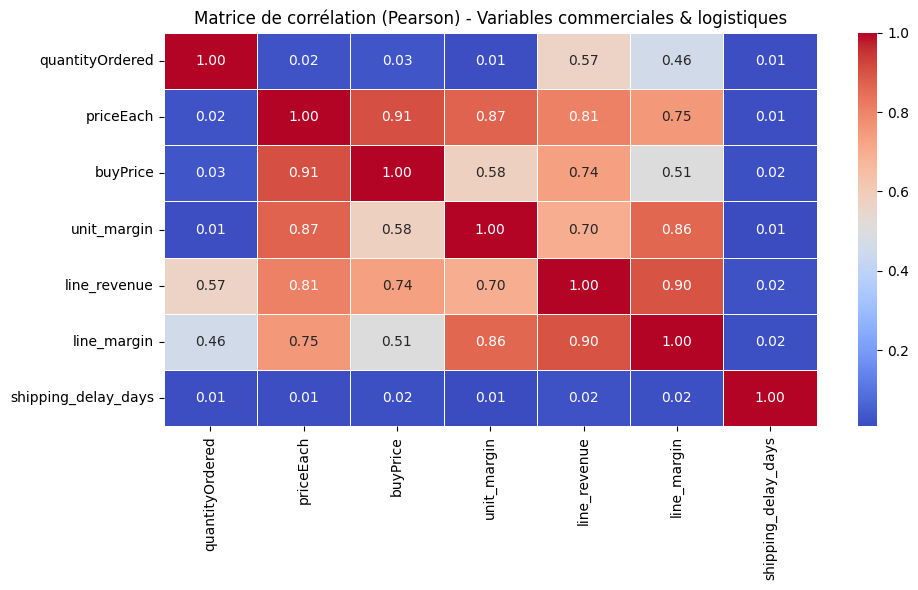

In [12]:
corr_pearson = df_num.corr(method="pearson")

plt.figure(figsize=(10, 6))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Matrice de corrélation (Pearson) - Variables commerciales & logistiques")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_corr_heatmap_pearson.png", dpi=300, bbox_inches="tight")
plt.show()

La HeatMap est utilisé pour identifier rapidement les relations les plus fortes entre variables facilitant l'analyse exploratoire et la prise de décision.

## Interprétation (principaux enseignements)

- La corrélation **quantityOrdered ↔ line_revenue** est attendue : plus on vend en volume, plus le CA de la ligne augmente.
- La relation **priceEach ↔ quantityOrdered** peut indiquer un effet de prix (si négative : volumes plus faibles sur produits chers).
- **shipping_delay_days** permet de vérifier si la logistique est liée aux ventes/marges (souvent corrélations faibles, mais à surveiller).
- Spearman confirme si les tendances restent vraies même en présence d’outliers ou de distributions asymétriques.